# Đại số Tuyến tính & Giải tích (Linear Algebra & Calculus)

Toán học là ngôn ngữ biểu diễn của Học máy. Phần này tóm tắt các khái niệm Đại số tuyến tính và Giải tích cơ bản nhất được sử dụng để lập trình các thuật toán từ đầu (from scratch) bằng NumPy.

**1. Đại số Tuyến tính (Linear Algebra):**
*   **Vector & Ma trận:** Dữ liệu luôn được biểu diễn dưới dạng ma trận $X \in \mathbb{R}^{N \times D}$ (N mẫu, D đặc trưng).
*   **Tích vô hướng (Dot Product / Matrix Multiplication):** Thao tác tính toán sự kết hợp tuyến tính $\Phi w$, nền tảng của mọi mạng neuron và hồi quy.
*   **Chuẩn (Norm):** Đo lường độ lớn của vector. L1 Norm ($||w||_1$) và L2 Norm ($||w||_2$) được dùng làm các hạng tử phạt trong Lasso và Ridge Regularization.
*   **Ma trận nghịch đảo (Inverse) & Giả nghịch đảo (Pseudo-inverse):** Dùng để giải trực tiếp nghiệm đóng (Normal Equation).

**2. Giải tích (Calculus):**
*   **Đạo hàm riêng (Partial Derivative) & Gradient:** Gradient $\nabla_w \mathcal{L}$ là một vector chứa các đạo hàm riêng, luôn chỉ về hướng hàm số tăng nhanh nhất. Thuật toán Gradient Descent đi ngược lại hướng này để tìm cực tiểu.
*   **Quy tắc chuỗi (Chain Rule):** Cơ chế toán học giúp phân rã đạo hàm của các hàm phức tạp, là cốt lõi của thuật toán Lan truyền ngược (Backpropagation).

In [5]:
import numpy as np

# 1. Khởi tạo Vector và Ma trận
x = np.array([1, 2, 3])
y = np.array([4, 5, 6])
A = np.array([[1, 2], [3, 4], [5, 6]])  # Kích thước (3, 2)
B = np.array([[7, 8, 9], [10, 11, 12]]) # Kích thước (2, 3)

# 2. Tích vô hướng (Dot Product) và Nhân ma trận
dot_product = np.dot(x, y) # 1*4 + 2*5 + 3*6 = 32
C = A @ B                  # Kích thước (3, 3). Có thể dùng np.matmul(A, B)

# 3. Tính chuẩn (Norm)
l1_norm = np.linalg.norm(x, ord=1) # L1: |1| + |2| + |3| = 6
l2_norm = np.linalg.norm(x, ord=2) # L2: sqrt(1^2 + 2^2 + 3^2) = 3.7416

# 4. Ma trận giả nghịch đảo (Pseudo-inverse)
# Áp dụng giải nghiệm đóng: w = (A^T A)^-1 A^T y
A_pinv = np.linalg.pinv(A) # Kích thước (2, 3)

print("--- Kết quả tính toán Đại số tuyến tính ---")
print(f"Dot product (x.y): {dot_product}")
print(f"Ma trận C (A @ B):\n{C}")
print(f"L2 Norm của x: {l2_norm:.4f}")
print(f"Ma trận giả nghịch đảo của A:\n{A_pinv}")

--- Kết quả tính toán Đại số tuyến tính ---
Dot product (x.y): 32
Ma trận C (A @ B):
[[ 27  30  33]
 [ 61  68  75]
 [ 95 106 117]]
L2 Norm của x: 3.7417
Ma trận giả nghịch đảo của A:
[[-1.33333333 -0.33333333  0.66666667]
 [ 1.08333333  0.33333333 -0.41666667]]


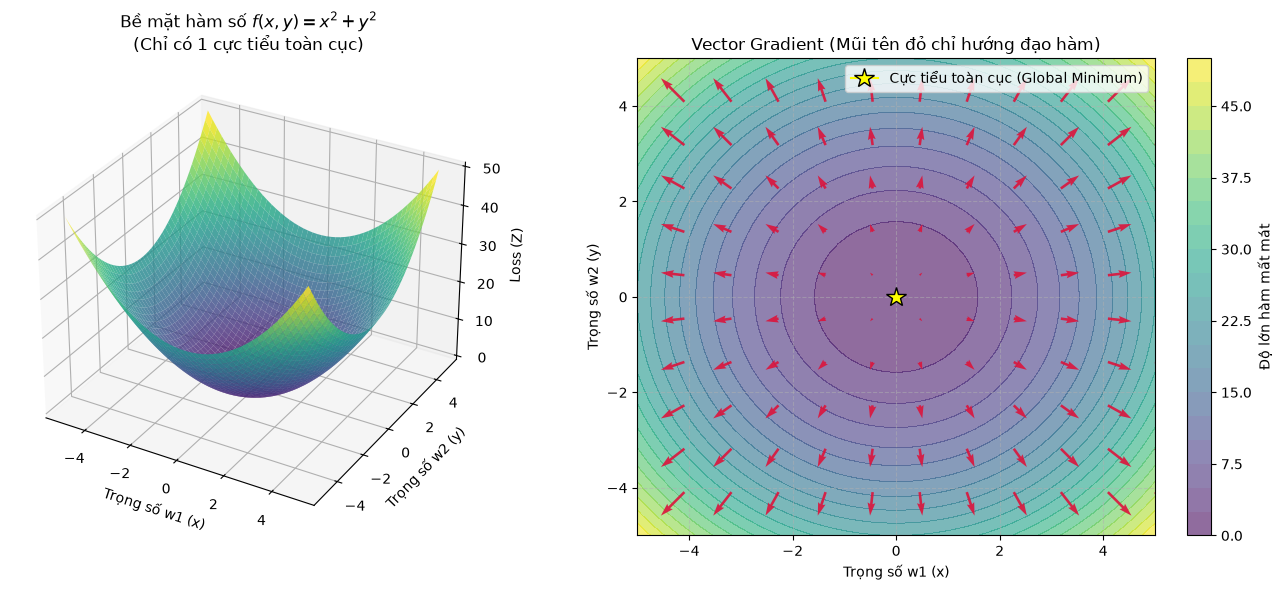

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Bề mặt hàm mất mát giả định: f(x, y) = x^2 + y^2 (Paraboloid lồi)
def f(x, y):
    return x**2 + y**2

# Đạo hàm riêng (Gradient): df/dx = 2x, df/dy = 2y
def gradient(x, y):
    return np.array([2*x, 2*y])

# Tạo lưới không gian dữ liệu
x = np.linspace(-5, 5, 50)
y = np.linspace(-5, 5, 50)
X, Y = np.meshgrid(x, y)
Z = f(X, Y)

# Thiết lập Figure
fig = plt.figure(figsize=(14, 6))

# Đồ thị 1: Bề mặt 3D
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(X, Y, Z, cmap='viridis', alpha=0.8, edgecolor='none')
ax1.set_title("Bề mặt hàm số $f(x, y) = x^2 + y^2$\n(Chỉ có 1 cực tiểu toàn cục)")
ax1.set_xlabel("Trọng số w1 (x)")
ax1.set_ylabel("Trọng số w2 (y)")
ax1.set_zlabel("Loss (Z)")

# Đồ thị 2: Bản đồ đường viền (Contour) và Vector Gradient
ax2 = fig.add_subplot(122)
contour = ax2.contourf(X, Y, Z, levels=20, cmap='viridis', alpha=0.6)
plt.colorbar(contour, ax=ax2, label="Độ lớn hàm mất mát")

# Tạo lưới thưa hơn để vẽ vector hướng (Quiver plot)
x_q = np.linspace(-5, 5, 12)
y_q = np.linspace(-5, 5, 12)
X_q, Y_q = np.meshgrid(x_q, y_q)
U, V = gradient(X_q, Y_q)

# Vẽ mũi tên Gradient (Luôn hướng ra xa tâm -> Hướng tăng dốc nhất)
ax2.quiver(X_q, Y_q, U, V, color='crimson', scale=180, alpha=0.9)
ax2.plot(0, 0, marker='*', color='yellow', markersize=15, markeredgecolor='black', label="Cực tiểu toàn cục (Global Minimum)")
ax2.set_title("Vector Gradient (Mũi tên đỏ chỉ hướng đạo hàm)")
ax2.set_xlabel("Trọng số w1 (x)")
ax2.set_ylabel("Trọng số w2 (y)")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()